In [37]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgbm
# 데이터 분할 및 전처리
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 특성 선택
from sklearn.feature_selection import SequentialFeatureSelector

# 하이퍼파라미터 튜닝
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve
# 모델 평가 지표
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# 데이터 시각화
import seaborn as sns

#파이프라인 / encoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer
from lightgbm import LGBMClassifier


# 1. 데이터 로드

In [38]:
df = pd.read_csv('train.csv')
df = df.drop(columns=['duration','ID'])  # ID, duration 제거
y = df['label']
X = df.drop(columns=['label'])
test = pd.read_csv('test.csv')

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split( X, y, test_size=0.2, stratify=y, )


# 파생변수 생성(함수)

## 수치형 변수 (로그변환해야하는 이유)

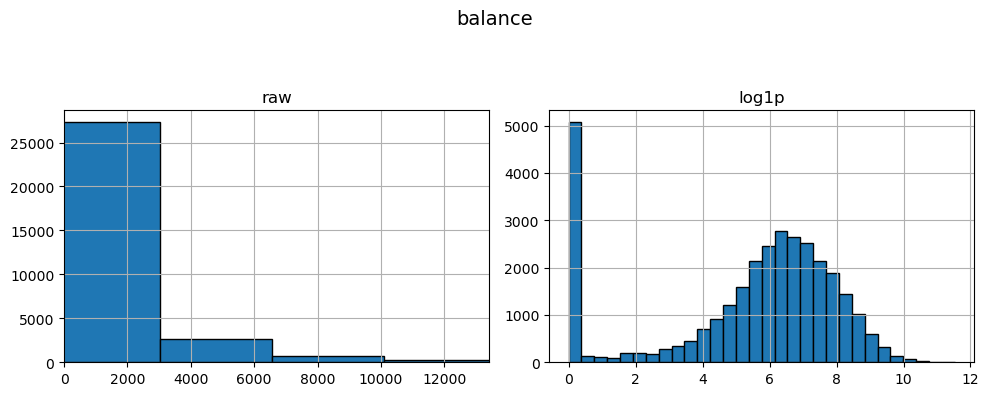

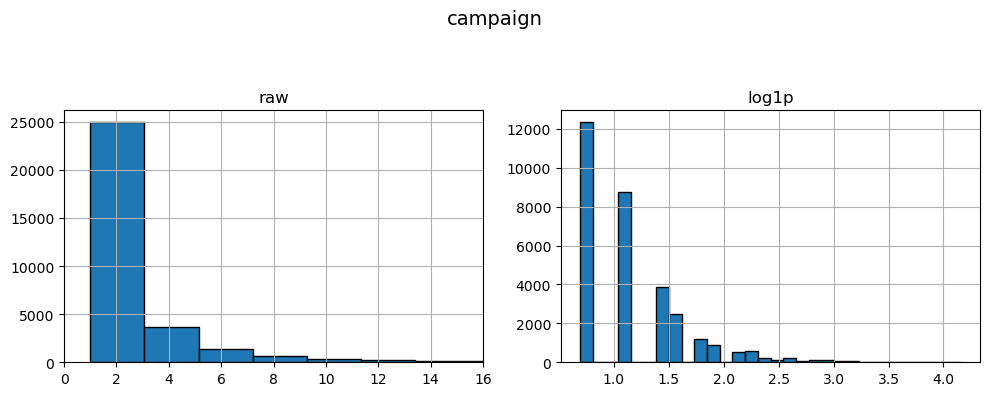

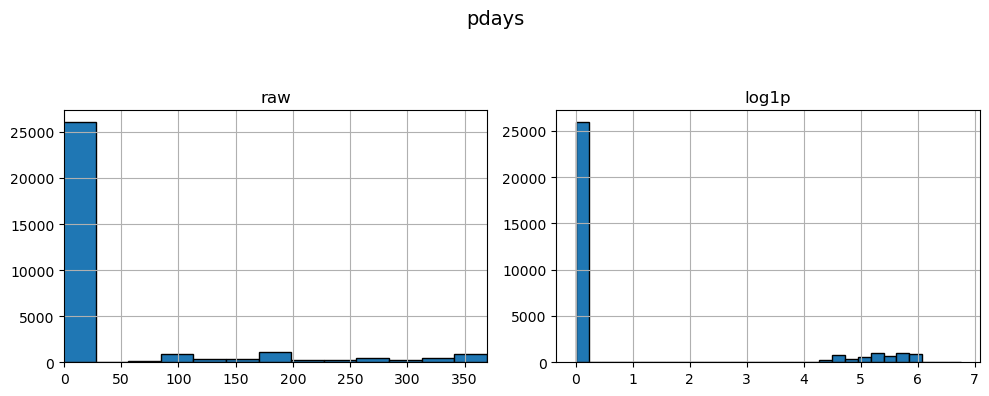

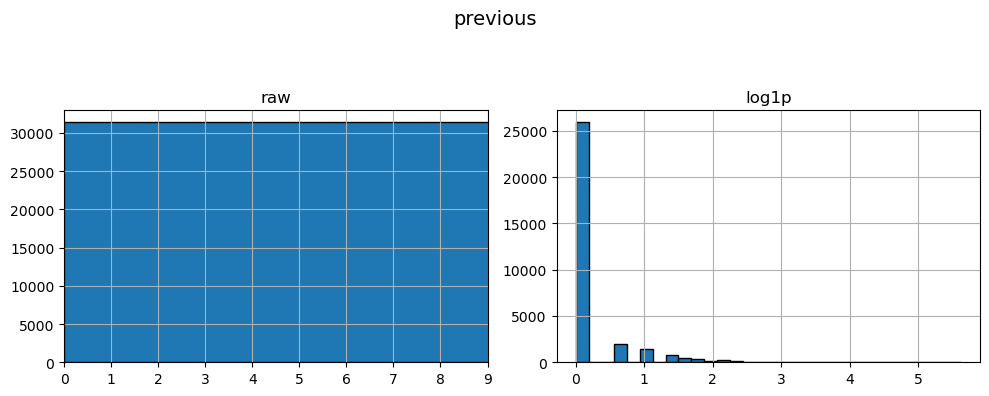

In [40]:
import matplotlib.pyplot as plt
import numpy as np

num_cols = ['balance','campaign','pdays','previous']

for col in num_cols:
    data = df[col].copy()
    
    # 1) 로그 변환분과 원본 비교를 위한 서브플롯
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(col, fontsize=14)
    
    #  원본 분포 — x축 제한
    axes[0].hist(data, bins=30, edgecolor='k')
    axes[0].set_title('raw')
    axes[0].set_xlim(0, np.percentile(data.replace(999, np.nan).dropna(), 99))  
    # 99백분위까지만 잘라서 메인 분포 확인
    axes[0].grid(True)
    
    # 로그1p 변환 후
    log_data = np.log1p(data.clip(lower=0))
    axes[1].hist(log_data, bins=30, edgecolor='k')
    axes[1].set_title('log1p')
    axes[1].grid(True)
    
    plt.tight_layout(rect=[0, 0, 1, 0.9])
    plt.show()


In [41]:
def combined_feat_eng(df):
    df = df.copy()
    
    # 1) education → 순서형
    edu_map = {'unknown':0, 'primary':1, 'secondary':2, 'tertiary':3}
    df['education_ord'] = df['education'].map(edu_map)
    
    # 2) marital 플래그
    df['is_single']   = (df['marital']=='single').astype(int)
    df['is_married']  = (df['marital']=='married').astype(int)
    df['is_divorced'] = (df['marital']=='divorced').astype(int)
    
    # 3) job 그룹화
    job_map = {
        'blue-collar':'manual', 'housemaid':'manual',
        'services':'service',  'technician':'service',
        'admin.':'whitecollar','management':'whitecollar','self-employed':'whitecollar',
        'retired':'retired',   'student':'student',    'unemployed':'unemployed',
        'entrepreneur':'other','unknown':'other'
    }
    df['job_grp'] = df['job'].map(job_map)
    
    # 4) balance 로그 변환
    min_bal = df['balance'].min()
    df['balance_shifted'] = df['balance'] - min_bal + 1
    df['balance_log']     = np.log(df['balance_shifted'])
    
    # 5) campaign 구간화
    df['campaign_bin'] = pd.cut(
    df['campaign'],
    bins=[0,1,3,5, df['campaign'].max()],
    labels=['1','2-3','4-5','>5']
    )
    
    # 6) pdays → 이진+구간
    df['was_contacted'] = (df['pdays'] != -1).astype(int)    
    df['pdays_bin'] = pd.cut(
        df['pdays'],
        bins=[-1,0,30,180,999],
        labels=['no_contact','<=1m','1m-6m','>6m']
    )
    
    # 7) credit 통합
    df['any_credit'] = ((df['housing']=='yes') | (df['loan']=='yes')).astype(int)
    
    # 8) day 순환 변환
    m = df['day']
    df['day_sin'] = np.sin(2*np.pi * m / 31)
    df['day_cos'] = np.cos(2*np.pi * m / 31)

    month_map = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                 'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
    m = df['month'].map(month_map)
    df['month_sin'] = np.sin(2*np.pi * m / 12)
    df['month_cos'] = np.cos(2*np.pi * m / 12)

    # 10) default 플래그
    df['is_default'] = (df['default']=='yes').astype(int)
    
    #11) precious log
    df['previous_log']  = np.log1p(df['previous'])
    
    return df

In [44]:
feat_eng = FunctionTransformer(combined_feat_eng, validate=False)

# 2) 파생 후 사용할 피처 리스트
# — 순서형·로그 변환·사이클·플래그형 모두 숫자형으로 처리
num_feats = [
    'education_ord',
    'balance_log',
    'day_sin', 'day_cos',
    'month_sin', 'month_cos',
    'is_single', 'is_married', 'is_divorced',
    'any_credit', 'was_contacted', 'is_default',
    'previous_log', 'age'
]

# — 파생한 카테고리형 변수만 인코딩
cat_feats = [
    'job_grp',
    'campaign_bin',
    'pdays_bin',
    'poutcome'
]

# 3) 숫자형 파이프라인: 스케일링
num_pipeline = Pipeline([
    ("scale", StandardScaler())
])

# 4) 범주형 파이프라인: 원-핫 인코딩
cat_pipeline = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# 5) ColumnTransformer: 숫자·범주형 묶어서 전처리
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_feats),
        ("cat", cat_pipeline,  cat_feats),
    ],
    remainder="drop",                # 나머지 원본 컬럼은 전부 버림
    verbose_feature_names_out=False  # 깔끔한 출력 이름
)

 

In [45]:
from imblearn.combine import SMOTETomek
from imblearn.pipeline        import Pipeline as ImbPipeline

ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

pipeline = ImbPipeline([
    ("feat_eng",   FunctionTransformer(combined_feat_eng, validate=False)),
    ("preprocess", preprocessor),          
    ("clf",        LGBMClassifier(class_weight={0:1, 1:ratio},random_state=42))
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipeline.fit(X_train, y_train)


[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001244 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 493
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 33
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


Pipeline(steps=[('feat_eng',
                 FunctionTransformer(func=<function combined_feat_eng at 0x16b471800>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['education_ord',
                                                   'balance_log', 'day_sin',
                                                   'day_cos', 'month_sin',
                                                   'month_cos', 'is_single',
                                                   'is_married', 'is_divorced',
                                                   'any_credit',
                                                   'was_contacted',
                                                   'is_default', 'previous_log',
                                                   'age']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['job_grp', 'campaign_bin',
                                                   'pdays_bin', 'poutcome'])],
                                   verbose_feature_names_out=False)),
                ('clf',
                 LGBMClassifier(class_weight={0: 1,
                                              1: np.float64(7.547265361242403)},
                                random_state=42))])

In [46]:
y_pred = pipeline.predict(X_val)
print("F1-score:", f1_score(y_val, y_pred))


F1-score: 0.3971462544589774


- F1-score: 0.33104799216454456 
    - 이 f1 day 와 month 에 대해 순환 처리 cos, sin 에 대해 했을 때 f1 스코어

- (r)F1-score: 0.3241706161137441
    - month 에 대해서 summer , winter, vacation 으로 나눴을 떄 f1 스코어

ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

pipeline = ImbPipeline([
    ("feat_eng",   FunctionTransformer(combined_feat_eng, validate=False)),
    ("preprocess", preprocessor),            # ColumnTransformer
    ("clf",        LGBMClassifier(class_weight={0:1, 1:ratio},random_state=42))
])

- 이렇게 가져 갔을 때, F1스코어가 완전히 높아졌음 value counts 한 다음에 weight 주는게 좋은 방향일수도!

In [ ]:
from sklearn.metrics import precision_recall_curve

# 1) 밸리데이션 세트에 대한 예측 확률
y_proba = pipeline.predict_proba(X_val)[:,1]

# 2) precision–recall 커브에서 F1 계산
prec, rec, thr = precision_recall_curve(y_val, y_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = f1_scores.argmax()
best_threshold = thr[best_idx]
print(f"Best threshold={best_threshold:.3f}, F1={f1_scores[best_idx]:.4f}")

# 3) 이 임계값으로 재분류
y_pred_opt = (y_proba >= best_threshold).astype(int)
print("Optimized F1:", f1_score(y_val, y_pred_opt))


Best threshold=0.601, F1=0.4203
Optimized F1: 0.4203102961918195


In [ ]:
#Best threshold=0.215, F1=0.4270
# Optimized F1: 0.42699724517906334




- (r)근데 ratio 로 ImbPipeline 설정했을 때 threshold 값이 안나오긴 하네염..

In [ ]:
#Best threshold=0.601, F1=0.4203
#Optimized F1: 0.4203102961918195

# 하이퍼파라미터 튜닝

In [ ]:
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from sklearn.metrics import f1_score

# 1) objective 정의: 각 trial마다 파이프라인을 새로 생성해 학습 → 검증 F1 반환
def objective(trial):
    # ─── 하이퍼파라미터 공간 ────────────────────────────────────────
    params = {
        'n_estimators':    trial.suggest_int('n_estimators', 100, 1000, step=100),
        'learning_rate':   trial.suggest_float('learning_rate', 1e-3, 1e-1, log=True),
        'num_leaves':      trial.suggest_int('num_leaves', 16, 128, step=16),
        'max_depth':       trial.suggest_int('max_depth', 3, 12),
        'reg_alpha':       trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda':      trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'colsample_bytree':trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
    }
    # ─── trial 전용 파이프라인 ────────────────────────────────────────
    trial_pipe = ImbPipeline([
        ("feat_eng",   feat_eng),
        ("preprocess", preprocessor),
        ("smt",        SMOTETomek(random_state=42)),
        ("clf",        LGBMClassifier(
                           **params,
                           class_weight="balanced",
                           random_state=42
                       )),
    ])

    # ─── fit & eval ───────────────────────────────────────────────────
    trial_pipe.fit(X_train, y_train)
    y_pred = trial_pipe.predict(X_val)
    return f1_score(y_val, y_pred)

# 2) Sampler & Pruner 설정 (optional)
sampler = TPESampler(seed=42)
pruner  = MedianPruner(n_startup_trials=5, n_warmup_steps=10)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    pruner=pruner,
    study_name="deposit_f1_opt"
)

# 3) 탐색 실행
study.optimize(objective, n_trials=50, timeout=60*30)  # 50 trials or 30분 중 빨리 끝나는 쪽

print("▶ Best F1:", study.best_value)
print("▶ Best params:", study.best_params)

[I 2025-05-26 17:18:05,419] A new study created in memory with name: deposit_f1_opt


[LightGBM] [Info] Number of positive: 22167, number of negative: 22167
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003207 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6496
[LightGBM] [Info] Number of data points in the train set: 44334, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with pos

[I 2025-05-26 17:18:11,074] Trial 0 finished with value: 0.25077081192189105 and parameters: {'n_estimators': 400, 'learning_rate': 0.07969454818643933, 'num_leaves': 96, 'max_depth': 8, 'reg_alpha': 0.004207988669606638, 'reg_lambda': 0.004207053950287938, 'colsample_bytree': 0.5290418060840998, 'subsample': 0.9330880728874675}. Best is trial 0 with value: 0.25077081192189105.


[LightGBM] [Info] Number of positive: 22167, number of negative: 22167
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002341 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6496
[LightGBM] [Info] Number of data points in the train set: 44334, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


[I 2025-05-26 17:18:14,337] Trial 1 finished with value: 0.3186372745490982 and parameters: {'n_estimators': 700, 'learning_rate': 0.02607024758370768, 'num_leaves': 16, 'max_depth': 12, 'reg_alpha': 2.136832907235876, 'reg_lambda': 0.0070689749506246055, 'colsample_bytree': 0.5909124836035503, 'subsample': 0.5917022549267169}. Best is trial 1 with value: 0.3186372745490982.


...

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 22167, number of negative: 22167
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002373 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6496
[LightGBM] [Info] Number of data points in the train set: 44334, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with pos

[I 2025-05-26 17:21:30,367] Trial 48 finished with value: 0.3916786226685796 and parameters: {'n_estimators': 100, 'learning_rate': 0.002649006825627099, 'num_leaves': 128, 'max_depth': 7, 'reg_alpha': 0.3822655791230797, 'reg_lambda': 1.8884447990695645, 'colsample_bytree': 0.8980241383558532, 'subsample': 0.5965596599446659}. Best is trial 46 with value: 0.4039334341906203.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number 

[I 2025-05-26 17:21:32,231] Trial 49 finished with value: 0.3566666666666667 and parameters: {'n_estimators': 200, 'learning_rate': 0.006639882307437701, 'num_leaves': 128, 'max_depth': 6, 'reg_alpha': 0.7788225423885984, 'reg_lambda': 4.236103693832719, 'colsample_bytree': 0.6931784252676635, 'subsample': 0.6783171987236205}. Best is trial 46 with value: 0.4039334341906203.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [ ]:
# 1) import the Matplotlib version
from optuna.visualization import plot_optimization_history
fig = plot_optimization_history(study)
fig.show()



In [ ]:
print("▶ Best F1:", study.best_value)
print("▶ Best params:", study.best_params)

▶ Best F1: 0.4039334341906203
▶ Best params: {'n_estimators': 100, 'learning_rate': 0.002472018585782415, 'num_leaves': 128, 'max_depth': 8, 'reg_alpha': 0.9461518466003893, 'reg_lambda': 6.505973118143229, 'colsample_bytree': 0.8939345644600866, 'subsample': 0.5911559831034492}


In [ ]:
#가장 처음 파생변수 그대로, smote 한 거.
#▶ Best F1: 0.4039334341906203
#▶ Best params: {'n_estimators': 100, 'learning_rate': 0.002472018585782415, 'num_leaves': 128, 'max_depth': 8, 'reg_alpha': 0.9461518466003893, 'reg_lambda': 6.505973118143229, 'colsample_bytree': 0.8939345644600866, 'subsample': 0.5911559831034492}